In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *
from time import time
import tifffile
import zarr

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
movie = tifffile.memmap("/home/kushal/lab/datasets/jason/soma/soma_memmapable.tif")[:2_500]

In [3]:
movie.shape

(2500, 512, 512)

In [4]:
movie = np.copy(movie[:, 128:-128, 128:-128])

In [5]:
movie_mean = movie.mean(axis=0)

In [6]:
movie_centered = movie - movie_mean

In [7]:
movie_centered.shape

(2500, 256, 256)

In [9]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")
iw.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [10]:
iw_raw = fpl.ImageWidget(movie_centered, cmap="gnuplot2")
iw_raw.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [21]:
iw_cropped = fpl.ImageWidget(movie_centered[:, 163:182, 153:172], cmap="gnuplot2")
iw_cropped.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

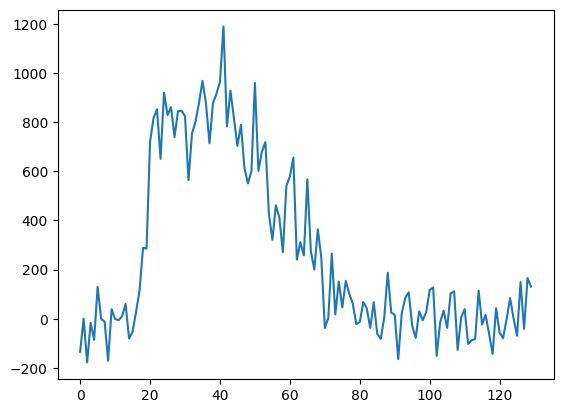

In [26]:
plt.plot(movie_centered[:, 163:182, 153:172].mean(axis=(1, 2))[1270:1400])

In [11]:
class TdSVD:
    def __init__(
        self,
        movie: np.ndarray,
        n_time_steps: int,
        delay: int,
    ):
        self.n_time_steps = n_time_steps
        self.movie_mean = movie.mean(axis=0)
        
        frame = movie[0]
        self.xdim, self.ydim = frame.shape[0], frame.shape[1]
        
        n_pixels = self.xdim * self.ydim
        n_timepoints = movie.shape[0]
        
        # self.A = np.memmap("./embedding.memmap", shape=(n_pixels * n_time_steps, n_timepoints - n_time_steps), dtype=np.float32, mode="w+")
        self.A = np.zeros(shape=(n_pixels * n_time_steps, n_timepoints - n_time_steps), dtype=np.float32)
        A_ixs = np.zeros(n_pixels * n_time_steps)
        
        for pixel_ix, (x, y) in tqdm(enumerate(product(range(self.xdim), range(self.ydim))), total=n_pixels):
            for step in range(n_time_steps):
                self.A[(n_time_steps * pixel_ix) + step] = np.roll(movie[:, x, y], shift=-delay * step)[:-n_time_steps]

        self.k, self.U, self.S, self.V = None, None, None, None
    
    def fit(self, k=6, **kwargs):
        self.k = k
        t0 = time()
        self.U, self.S, self.V = svds(self.A, k=k, **kwargs)
        self.U = self.U[:, ::-1]
        self.S = self.S[::-1]
        self.V = self.V[::-1, :]
        t1 = time()
        print(f"svd took: {t1 - t0:.02f} sec")

    def get_spatial(self):
        """
        Returns
        -------
        np.ndarray
            [n_time_steps, k, ydim, xdim]
        """
        return np.array([self.U.reshape((self.xdim, self.ydim, self.n_time_steps, self.k))[..., i, :].transpose(2, 0, 1) for i in range(self.n_time_steps)])

In [11]:
td_svd = TdSVD(
    movie=movie_centered,
    n_time_steps=40,
    delay=1,
)

100%|█████████████████████████████████████████████████████████████████████████████| 65536/65536 [10:57<00:00, 99.73it/s]


In [12]:
td_svd.fit(k=8)

svd took: 56.13 sec


In [12]:
import pickle

In [13]:
td_svd = pickle.load(open("./td_svd_soma.pickle", mode="rb"))

In [14]:
spatial = td_svd.get_spatial()

In [15]:
spatial.shape

(40, 8, 256, 256)

In [17]:
iw_steps = fpl.ImageWidget(
    data=[spatial[step] for step in range(td_svd.n_time_steps)],
    names=[f"step-{i}" for i in range(td_svd.n_time_steps)],
    grid_plot_kwargs={"size": (1500, 400)}
)
iw_steps.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

In [19]:
iw_steps.cmap = "gnuplot2"

In [20]:
spatial.shape

(40, 8, 256, 256)

In [21]:
from ipywidgets import HBox

In [19]:
iw_steps = fpl.ImageWidget(
    data=[spatial[:, k_step] for k_step in range(td_svd.k)],
    names=[f"vector-{i}" for i in range(td_svd.k)],
    grid_plot_kwargs={"size": (1500, 400)}
)

plot_lines = fpl.Plot()
plot_lines.docks["right"].size = 70

# legend = fpl.Legend(plot_lines.docks["right"])
# for i, (vi, c) in enumerate(zip(td_svd.V, ["red", "orange", "yellow", "green", "blue", "purple"])):
#     l = plot_lines.add_line(vi, colors=c, name=f"{i}")
    # legend.add_graphic(l, label=f"{i}---")

# plot_lines.show()

iw_steps.show()
# HBox([iw_steps.widget, plot_lines.widget])

RFBOutputContext()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

In [65]:
for g in plot_lines.graphics:
    g.colors[:, -1] = 0.5

In [35]:
spatial.shape

(20, 6, 312, 312)

In [37]:
np.prod(movie_centered, spatial[19, 1])

(312, 312)

In [34]:
iw.cmap = "viridis_r"

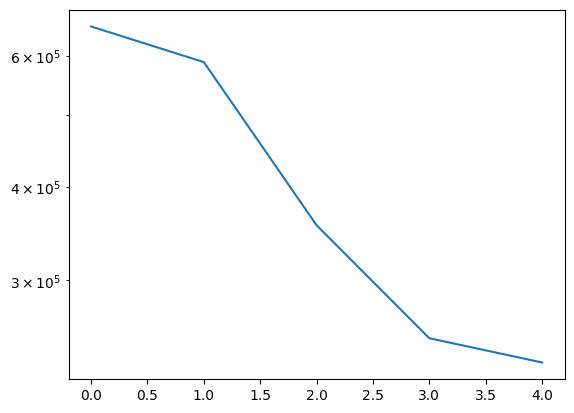

In [14]:
plt.plot(td_svd.S[1:])
plt.yscale("log")
# plt.xscale("log")

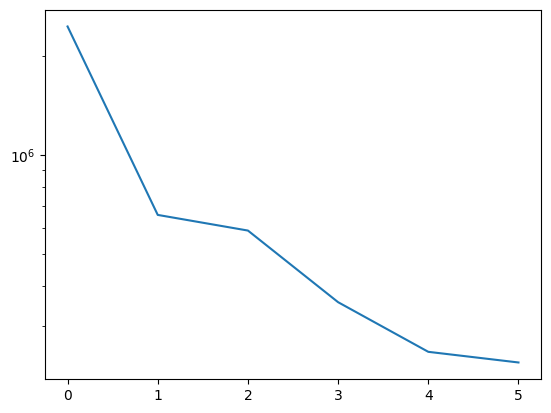

In [15]:
plt.plot(td_svd.S)
plt.yscale("log")
# plt.xscale("log")

In [16]:
td_svd.S / 10**5

array([24.6937775 ,  6.56922188,  5.8849625 ,  3.55727906,  2.50984359,
        2.32883203])

In [17]:
%matplotlib ipympl

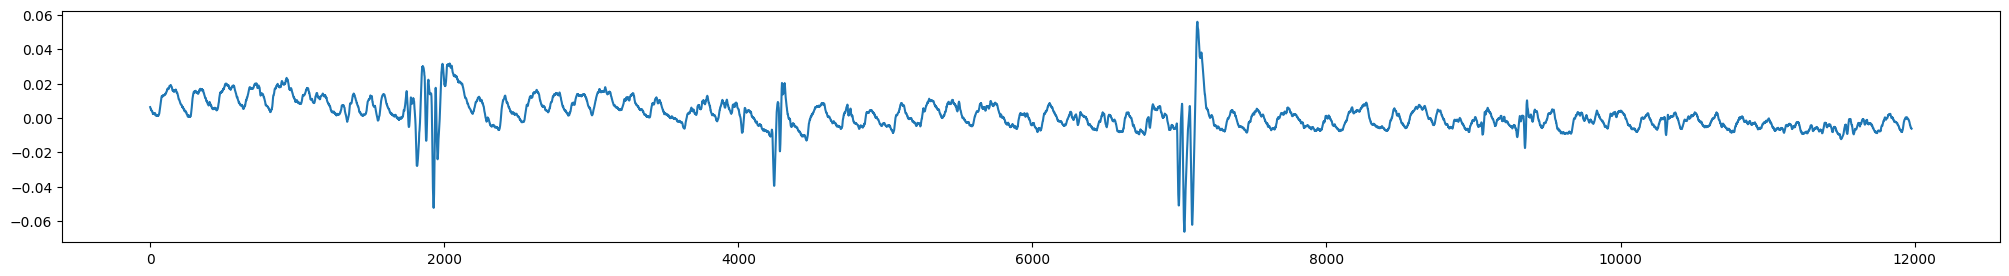

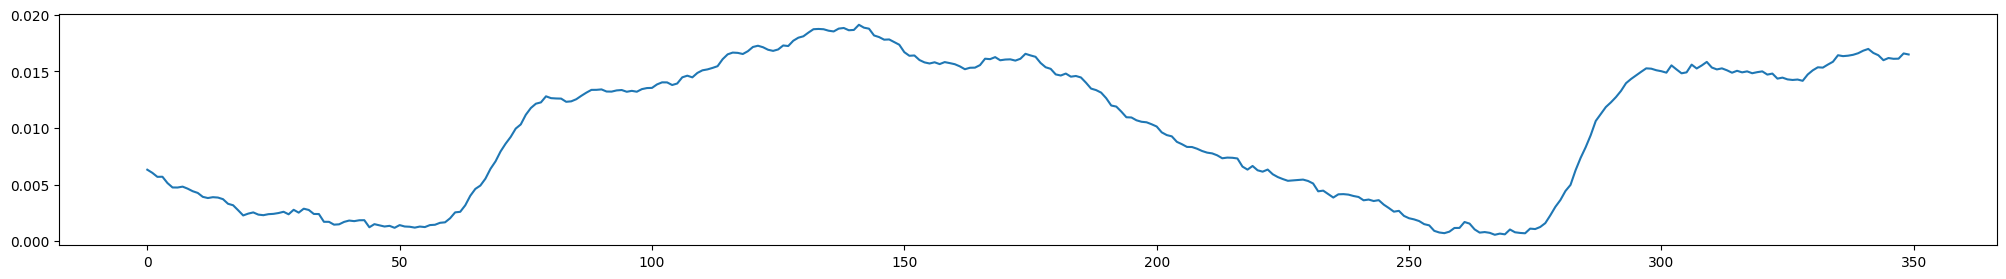

In [17]:
i = 1

fig = plt.figure(figsize=(25, 3))
plt.plot(td_svd.V[i])
plt.show()

fig = plt.figure(figsize=(25, 3))
plt.plot(td_svd.V[i][:350])
plt.show()

<Axes: >

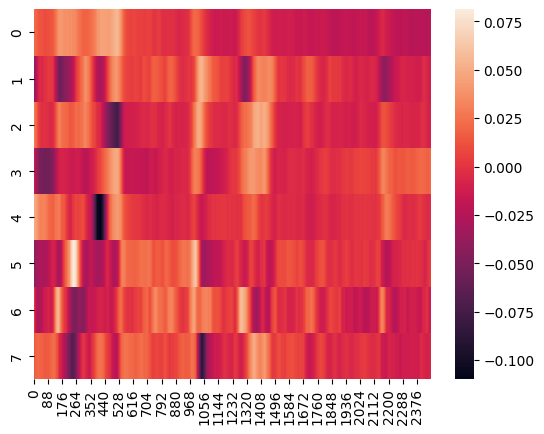

In [27]:
sns.heatmap(td_svd.V)

<Axes: >

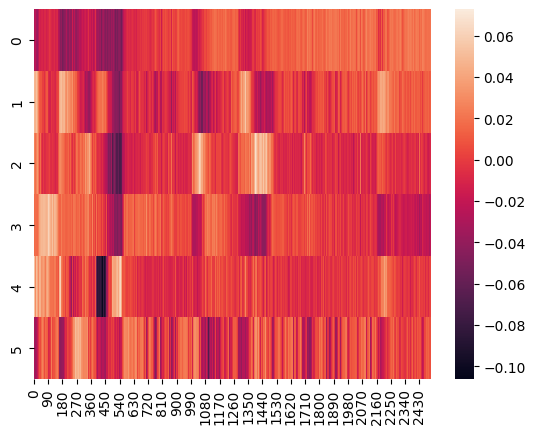

In [28]:
sns.heatmap(v)

In [14]:
u, s, v = svds(movie_centered.reshape(movie_centered.shape[0], movie_centered.shape[1] * movie_centered.shape[2]).T, k=6)

In [15]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

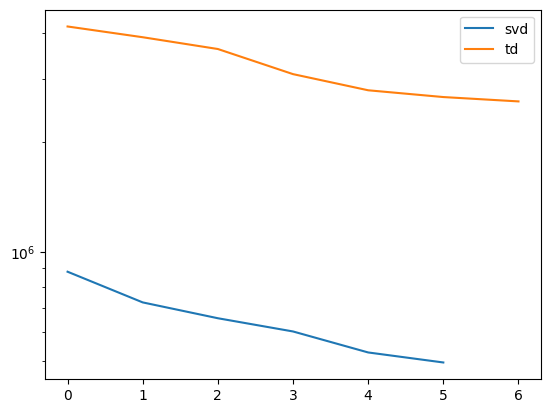

In [16]:
plt.plot(s[:], label="svd")
plt.plot(td_svd.S[1:], label="td")
plt.yscale("log")
plt.legend()
# plt.xscale("log")

In [15]:
s / 10**5

array([5.93849149, 1.6923099 , 1.19604976, 1.04251914, 0.81696902,
       0.75185843])

In [16]:
u.shape

(97344, 6)

In [17]:
iw_svd = fpl.ImageWidget([a for a in u.T.reshape(6, movie_centered.shape[1], movie_centered.shape[2])], grid_shape=(3, 2), cmap="gnuplot2")
iw_svd.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

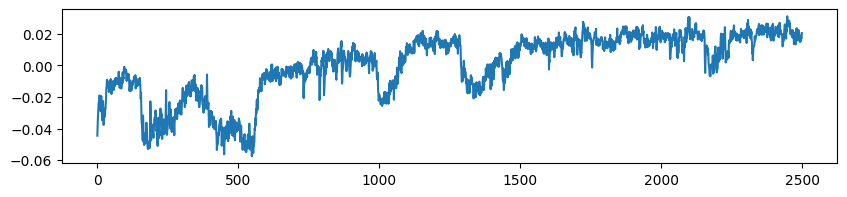

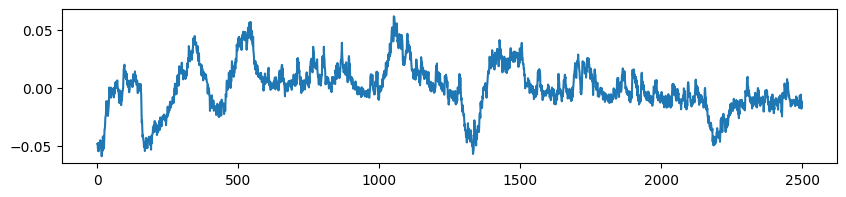

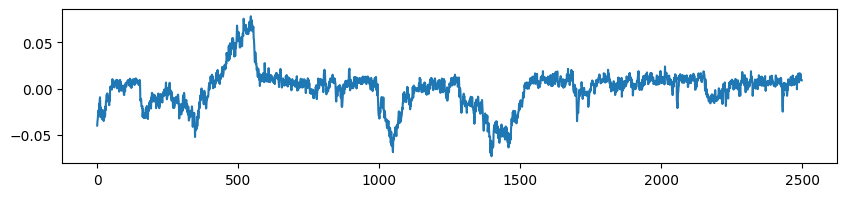

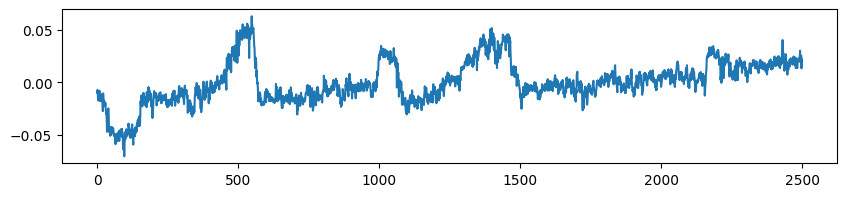

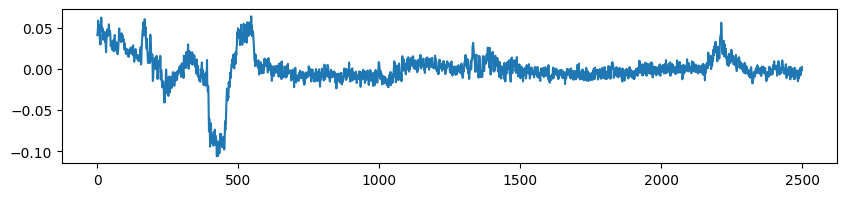

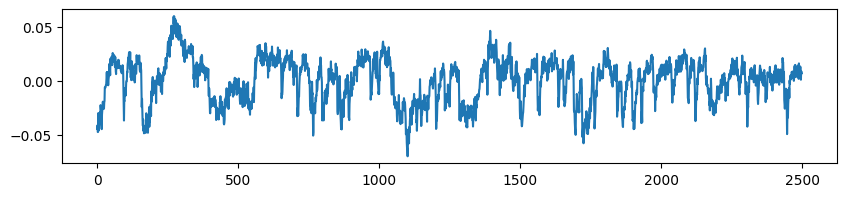

In [22]:
for vi in v:
    fig = plt.figure(figsize=(10, 2))
    plt.plot(vi)
    plt.show()

In [45]:
iw_svd.cmap = ["gnuplot2_r", "gnuplot2_r", "gnuplot2", "gnuplot2_r", "gnuplot2", "gnuplot2"]

In [59]:
%matplotlib ipympl

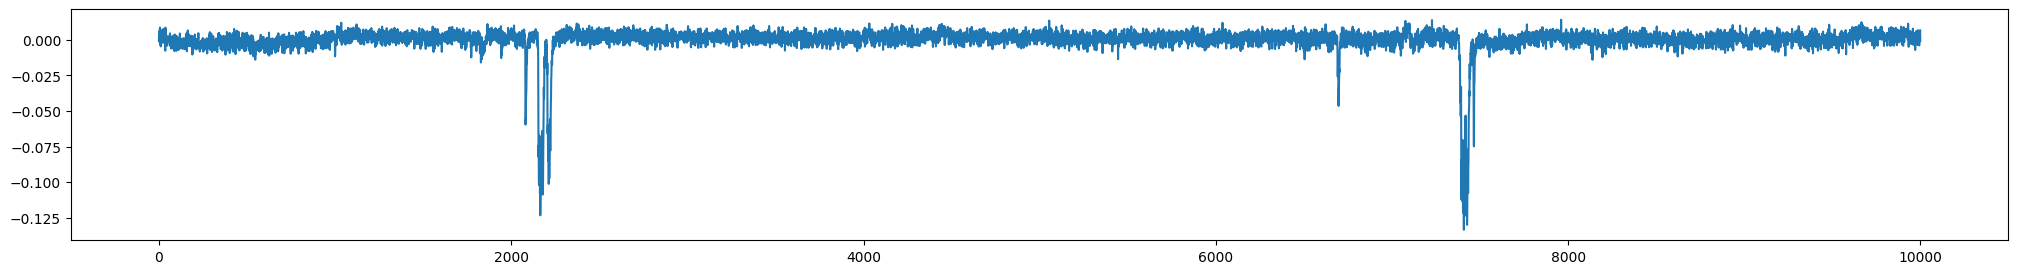

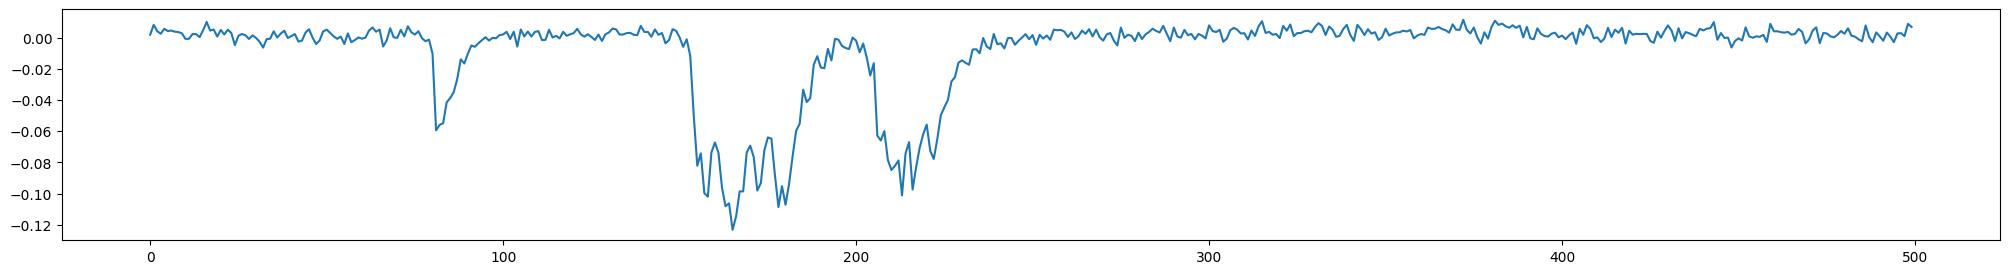

In [23]:
i = 3

fig = plt.figure(figsize=(25, 3))
plt.plot(v[i])
plt.show()

fig = plt.figure(figsize=(25, 3))
plt.plot(v[i][2000:2500])
plt.show()

In [20]:
from ipywidgets import VBox

In [44]:
plot_line = fpl.Plot()

iw_ = fpl.ImageWidget(movie_centered, cmap="gnuplot2")

plot_line.show()

VBox([iw_.show(), plot_line.show()])

RFBOutputContext()

RFBOutputContext()

In [ ]:
plot_line.add_line(td_svd.V[1], name="td-1")
legend = fpl.Legend(plot_line.docks["top"])


sel = plot_line.graphics[0].add_linear_selector()

In [54]:
plot_line["svd-2"].data[:, 1] = - plot_line["svd-2"].data[:, 1]

In [40]:
iw_.cmap = "seismic"

In [41]:
plot_line.add_line(-v[1], colors="r", name="svd-1")

<weakproxy at 0x7f205a16efc0 to LineGraphic at 0x7f205a01bd10>

In [55]:
for g in plot_line.graphics:
    if "svd" in g.name:
        g.visible = False

In [42]:
plot_line.add_line(-v[2], colors="cyan", name="svd-2")

<weakproxy at 0x7f205a1a72e0 to LineGraphic at 0x7f205a020f90>

In [57]:
plot_line.add_line(td_svd.V[2], colors="yellow", name="td-2")

<weakproxy at 0x7f205a004ea0 to LineGraphic at 0x7f205a017f90>

In [56]:
plot_line.delete_graphic(plot_line.graphics[-1])

In [44]:
for g in plot_line.graphics:
    g.colors[:, -1] = 0.4

In [45]:
plot_line.graphics[0].thickness = 4

In [46]:
plot_line.graphics[-1].thickness = 3

In [47]:
iw_.cmap = "gnuplot2"

In [48]:
sel.add_ipywidget_handler(iw_.sliders["t"])

In [49]:
iw_.window_funcs = {"t": (np.mean, 11)}